In [ ]:
import sys
import pandas as pd
import os
import dotenv

dotenv.load_dotenv(dotenv_path='/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Maryland/bechmark analysis pipeline/benchmark-analysis/.env')

sys.path.append('/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Personal Projects/pairadigm')
import pairadigm as pr

True

In [2]:
sample = pd.read_csv('Data/annotation_sample.csv')
sample

,id,split,V,A,D,text
0,Italy_4868_4942,train,3.50,3.50,2.90,have a happy vacation that place looks fascina...
1,112C-L015_1504_1606,train,3.29,2.86,3.00,"It can help purchase clothing, school supplies..."
2,SemEval_185,test,2.30,3.40,2.80,Squirrel jumps boy in park; rabies suspected
3,wsj_0120_2997_3087,train,3.22,3.00,3.22,"""The thing that will really break this market ..."
4,captured_moments_24998_25039,train,2.80,3.10,3.60,"It's unforgiveable, but you're forgiven."""
5,SemEval_1148,train,2.67,2.89,3.00,One search does not fit all
6,How_soon-Lebron-James_2916_2975,train,3.30,3.30,3.50,That the only thing that matters is winning a ...
7,hotel-california_8179_8272,test,3.62,3.62,3.12,I wondered if the food delivered to my quarter...
8,Fermentation_Eminent-Domain_2413_2562,test,3.11,2.78,3.11,"Honore Comfort, Executive Director of the Sono..."
9,NYTnewswire2_7491_7738,train,3.70,3.50,3.40,"Also on Feb. 12, a week before the ice dancing..."


In [3]:
# Read a txt file with prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    arousal_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

In [4]:
p_val = pr.Pairadigm(
    sample, 
    item_id_name='id',
    text_name='text',
    cgcot_prompts=val_prompts,
    model_name='gpt-4.1',
    api_key=os.getenv('OPENAI_API_KEY'),
    target_concept='valence'
)

p_aro = pr.Pairadigm(
    sample, 
    item_id_name='id',
    text_name='text',
    cgcot_prompts=arousal_prompts,
    model_name='gpt-4.1',
    api_key=os.getenv('OPENAI_API_KEY'),
    target_concept='arousal'
)

p_dom = pr.Pairadigm(
    sample, 
    item_id_name='id',
    text_name='text',
    cgcot_prompts=dom_prompts,
    model_name='gpt-4.1',
    api_key=os.getenv('OPENAI_API_KEY'),
    target_concept='dominance'
)

In [24]:
pairs = p_val.pairwise_df[['item1', 'item2']].copy()

pairs_for_humans = pairs.merge(sample[['id', 'text']], left_on='item1', right_on='id').rename(columns={'text': 'text1'}).drop(columns=['id'])
pairs_for_humans = pairs_for_humans.merge(sample[['id', 'text']], left_on='item2', right_on='id').rename(columns={'text': 'text2'}).drop(columns=['id'])

pairs_for_humans.to_excel('Data/human annotations/pairs_for_human_annotation.xlsx', index=False)

## Exploration (ignore this)

In [6]:
for p in [p_val, p_aro, p_dom]:
    p.generate_breakdowns(rate_limit_per_minute=0)
    p.generate_pairings(breakdowns=True)
    p.generate_pairwise_annotations(max_workers=8)
    p.score_items(normalization_scale="negative-one-to-one")
    

Completed 50/293 comparisons
Completed 100/293 comparisons
Completed 150/293 comparisons
Completed 200/293 comparisons
Completed 250/293 comparisons
Bradley-Terry model fitted with 292 comparisons
Mean valence score: 0.087
Std valence score: 0.590
Score range: -1.000 to 1.000
25th percentile: -0.390
50th percentile (median): 0.172
75th percentile: 0.559

Highest scoring item on valence (score: 1.000):
Blessings to you.

Lowest scoring item on valence (score: -1.000):
"What is this?"
mean: 0.087
median: 0.172
std: 0.590
min: -1.000
max: 1.000
count: 50.000
Completed 50/293 comparisons
Completed 100/293 comparisons
Completed 150/293 comparisons
Completed 200/293 comparisons
Completed 250/293 comparisons
Bradley-Terry model fitted with 293 comparisons
Mean arousal score: 0.178
Std arousal score: 0.569
Score range: -1.000 to 1.000
25th percentile: -0.237
50th percentile (median): 0.184
75th percentile: 0.697

Highest scoring item on arousal (score: 1.000):
“We're revolting,”

Lowest scorin

In [8]:
p_val.scored_df

,id,split,V,A,D,text,CGCoT_Breakdown,Bradley_Terry_Score
0,Italy_4868_4942,train,3.50,3.50,2.90,have a happy vacation that place looks fascina...,Original Text: have a happy vacation that plac...,0.914728
1,112C-L015_1504_1606,train,3.29,2.86,3.00,"It can help purchase clothing, school supplies...","Original Text: It can help purchase clothing, ...",0.565252
2,SemEval_185,test,2.30,3.40,2.80,Squirrel jumps boy in park; rabies suspected,Original Text: Squirrel jumps boy in park; rab...,-0.114284
3,wsj_0120_2997_3087,train,3.22,3.00,3.22,"""The thing that will really break this market ...","Original Text: ""The thing that will really bre...",0.411982
4,captured_moments_24998_25039,train,2.80,3.10,3.60,"It's unforgiveable, but you're forgiven.""","Original Text: It's unforgiveable, but you're ...",0.542197
5,SemEval_1148,train,2.67,2.89,3.00,One search does not fit all,Original Text: One search does not fit all\nPr...,-0.896589
6,How_soon-Lebron-James_2916_2975,train,3.30,3.30,3.50,That the only thing that matters is winning a ...,Original Text: That the only thing that matter...,-0.265410
7,hotel-california_8179_8272,test,3.62,3.62,3.12,I wondered if the food delivered to my quarter...,Original Text: I wondered if the food delivere...,0.566422
8,Fermentation_Eminent-Domain_2413_2562,test,3.11,2.78,3.11,"Honore Comfort, Executive Director of the Sono...","Original Text: Honore Comfort, Executive Direc...",0.939845
9,NYTnewswire2_7491_7738,train,3.70,3.50,3.40,"Also on Feb. 12, a week before the ice dancing...","Original Text: Also on Feb. 12, a week before ...",0.384057


In [9]:
all_scores = sample.copy()
for p in [p_val, p_aro, p_dom]:
    new_df = p.scored_df.copy()
    new_df = new_df[['id', 'Bradley_Terry_Score']] if "Bradley_Terry_Score" in new_df.columns else new_df[['id', f'BT_Score_{p.target_concept}']]
    new_df.rename(columns={'Bradley_Terry_Score': f'BT_Score_{p.target_concept}'}, inplace=True)
    all_scores = new_df if all_scores is None else all_scores.merge(new_df, on='id')

all_scores

,id,split,V,A,D,text,BT_Score_valence,BT_Score_arousal,BT_Score_dominance
0,Italy_4868_4942,train,3.50,3.50,2.90,have a happy vacation that place looks fascina...,0.914728,0.942546,-0.121632
1,112C-L015_1504_1606,train,3.29,2.86,3.00,"It can help purchase clothing, school supplies...",0.565252,-0.349369,0.310369
2,SemEval_185,test,2.30,3.40,2.80,Squirrel jumps boy in park; rabies suspected,-0.114284,0.926339,0.497906
3,wsj_0120_2997_3087,train,3.22,3.00,3.22,"""The thing that will really break this market ...",0.411982,0.706360,0.925193
4,captured_moments_24998_25039,train,2.80,3.10,3.60,"It's unforgiveable, but you're forgiven.""",0.542197,0.822718,0.873218
5,SemEval_1148,train,2.67,2.89,3.00,One search does not fit all,-0.896589,-0.422862,-0.116927
6,How_soon-Lebron-James_2916_2975,train,3.30,3.30,3.50,That the only thing that matters is winning a ...,-0.265410,0.752167,0.937178
7,hotel-california_8179_8272,test,3.62,3.62,3.12,I wondered if the food delivered to my quarter...,0.566422,0.663820,-0.212250
8,Fermentation_Eminent-Domain_2413_2562,test,3.11,2.78,3.11,"Honore Comfort, Executive Director of the Sono...",0.939845,-0.198858,0.796531
9,NYTnewswire2_7491_7738,train,3.70,3.50,3.40,"Also on Feb. 12, a week before the ice dancing...",0.384057,0.803571,0.893069


In [10]:
all_scores.to_csv('Data/gpt_4-1_annotation_scores.csv', index=False)

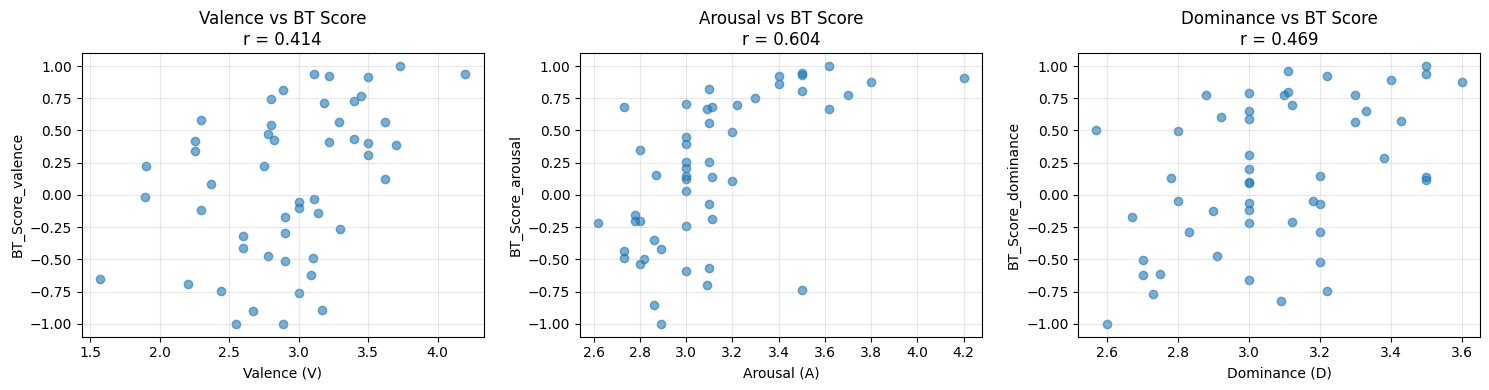

In [13]:
from scipy.stats import pearsonr

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Valence vs BT_Score_valence
corr_v, _ = pearsonr(all_scores['V'], all_scores['BT_Score_valence'])
axes[0].scatter(all_scores['V'], all_scores['BT_Score_valence'], alpha=0.6)
axes[0].set_xlabel('Valence (V)')
axes[0].set_ylabel('BT_Score_valence')
axes[0].set_title(f'Valence vs BT Score\nr = {corr_v:.3f}')
axes[0].grid(True, alpha=0.3)

# Arousal vs BT_Score_arousal
corr_a, _ = pearsonr(all_scores['A'], all_scores['BT_Score_arousal'])
axes[1].scatter(all_scores['A'], all_scores['BT_Score_arousal'], alpha=0.6)
axes[1].set_xlabel('Arousal (A)')
axes[1].set_ylabel('BT_Score_arousal')
axes[1].set_title(f'Arousal vs BT Score\nr = {corr_a:.3f}')
axes[1].grid(True, alpha=0.3)

# Dominance vs BT_Score_dominance
corr_d, _ = pearsonr(all_scores['D'], all_scores['BT_Score_dominance'])
axes[2].scatter(all_scores['D'], all_scores['BT_Score_dominance'], alpha=0.6)
axes[2].set_xlabel('Dominance (D)')
axes[2].set_ylabel('BT_Score_dominance')
axes[2].set_title(f'Dominance vs BT Score\nr = {corr_d:.3f}')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
p_val.save('Data/pairadigm_pickles/pairadigm_valence.pkl')
p_aro.save('Data/pairadigm_pickles/pairadigm_arousal.pkl')
p_dom.save('Data/pairadigm_pickles/pairadigm_dominance.pkl')